# Sequential Ergodic Exploration using Tensor Train (planar, with tilt)

Reference: S. Shetty, J. Silvério, S. Calinon, "Ergodic Exploration using Tensor Train: Applications in Insertion Tasks" (E2T2), arXiv:2101.04428, and its notebook, whose structure this one follows.

E2T2 explores one fixed reference distribution. For a sequential task this notebook adds two things, each kept in TT format:
- a **sliding target**: the reference holds only the taught datapoints within a lead of the current phase, behind it and ahead;
- a **forgetting statistic**: coverage fades, so after a failure the earlier stages count as uncovered again;

The task is a **peg-slide**: insert the peg into the slot of a block from above, then push the block along to the goal. The peg has a tilt, and a peg tilted too far for its depth jams in the slot; the clearance is so small that one step of the plant's noise at full depth can jam it. The push is physically impossible before the insertion has succeeded, and the taught motion never crosses or retraces itself, so progress along it is continuous. In each sequence of trials the block sits further from where it was taught than the slot's clearance, so the taught motion misses the slot.

A memory of failures across trials (negative target mass, marks in the statistic) is out of scope here: every form of it tried so far made the law worse.

In [1]:
import time
from dataclasses import dataclass
from multiprocessing import Pool

import numpy as np
import tt
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp
from tt.cross import rect_cross

### State space
The state is the tip's position and the peg's tilt, $\mathbf{x} = (x, y, z)$, with the tilt as a length, $z = D\theta$, $D$ the slot's depth: the sideways shift a tilt $\theta$ makes at the bottom of the slot, where it jams. Turning and moving are then measured by the displacement each makes where it matters, and one step cap and one noise serve all three axes.

The world is a box $[l_i, l_i + s_i]$ per axis: $[0, 1]$ for $x$ and $y$, and for $z$ the widest tilt the demonstrations reach (below). The law's cube $\Omega = \prod_i [a_i, a_i + L_i]$ extends beyond it by a margin $m_i$, $a_i = l_i - m_i$, $L_i = s_i + 2m_i$, with $K$ cosine functions per axis and $K^d$ coefficients. The margin is needed because every cosine $\phi_k$ has zero slope at the cube's faces: a state on a face gets no push off it from the law, and at a corner $\mathbf{b} = \mathbf{0}$. E2T2 keeps the state away from the faces with `pull2centre`; here the faces lie outside the world, so the world's own walls are all the state ever touches. $m_i = s_i / (2(K-1))$ is a quarter of the finest mode's period: at that distance from a face its slope peaks.


In [2]:
d = 3  # x, y and the tilt
K = 10  # basis functions per axis
WORLD = 1.0  # side of the world in x and y
print("Number of Fourier coefficients:", K**d)

Number of Fourier coefficients: 1000


### Fourier basis and its gradient in TT format
$$\begin{align*}
\phi^{(i)}_k(x) &= \cos\Big(\frac{\pi k (x - a_i)}{L_i}\Big), \quad k \in \{0, \ldots, K-1\}, \\
\mathbf{\Phi}(\mathbf{x}) &= \boldsymbol{\phi}^{(1)}(x_1) \circ \cdots \circ \boldsymbol{\phi}^{(d)}(x_d), \\
\nabla_i \mathbf{\Phi}(\mathbf{x}) &= \boldsymbol{\phi}^{(1)}(x_1) \circ \cdots \circ \frac{\partial \boldsymbol{\phi}^{(i)}(x_i)}{\partial x} \circ \cdots \circ \boldsymbol{\phi}^{(d)}(x_d).
\end{align*}$$
$\pi$ rather than the paper's $2\pi$, as in the E2T2 code: with $2\pi$ every basis function is symmetric about $L_i/2$. Both are rank-1 TTs.

In [3]:
def Phi(y, i):  # (K,) on axis i
    return np.cos(np.pi * (y - CUBE_LO[i]) * np.arange(K) / L[i])


def DPhi(y, i):  # (K,) on axis i
    return (-np.pi / L[i]) * np.arange(K) * np.sin(np.pi * (y - CUBE_LO[i]) * np.arange(K) / L[i])


def tt_phi_dphi(x):
    cores = [Phi(xi, i).reshape(1, -1, 1) for i, xi in enumerate(x)]
    dcores = [DPhi(xi, i).reshape(1, -1, 1) for i, xi in enumerate(x)]
    tt_phi = tt.vector.from_list(cores)
    tt_dphi = [tt.vector.from_list([*cores[:i], dcores[i], *cores[i + 1 :]]) for i in range(len(x))]
    return tt_phi, tt_dphi

### The task: a peg-slide
All lengths in cube units. A block of half-width $0.075$ stands on the floor, $y \in [0, 0.20]$, centred at $c$. A slot of depth $D = 0.15$, open at the top, reaches down to $y = 0.05$. The peg has half-width $w = 0.01$; its tip is the centre of its end face, and it tilts about the tip. The tip's play in the slot is $\pm(s - w)$ for a slot of half-width $s$, whatever the tilt. In each sequence the block starts at $c_0 + \Delta$, where $c_0 = 0.23$ is where it was taught.

- **Jam.** With the tip a depth $\delta$ below the block's top and tilt $\theta$, the peg below the top spans, from its lower bottom corner to where its other side crosses the top (two-point contact),
$$\mathrm{width}(\delta, \theta) = 2w\cos\theta + \ell \sin|\theta|, \qquad \ell = \frac{\delta + w \sin|\theta|}{\cos\theta},$$
$\ell$ the inserted length of that side. The peg fits while $\mathrm{width} \le 2s$. The walls stop the tilt, and the tilt stops the depth: a peg tilted too far for its depth cannot go deeper until it tilts back or withdraws. The tilt matters nowhere else.
- **Clearance.** $s$ is set so that one step of the plant's noise in tilt, $\theta_{\mathrm{n}} = \nu / D$, just fits at full depth: $2s = \mathrm{width}(D, \theta_{\mathrm{n}})$. One bad step at the bottom of the slot then jams the peg.
- **Barrier.** A wall at $x = 0.43$, clear of the block at the largest offset, $0.11$, stops the tip and the block until the tip has been within $0.015$ of the slot's floor. Then it is gone for good.
- **Push.** A tip in the slot carries the block sideways by its walls. The block never moves left of where it started, and it moves only through the slot.
- **Goal.** The block's centre and the tip both beyond $x = 0.80$.
- **Contact.** Faces stop the tip and let it slide along them.

`in_dead_end` and `jammed` are for the evaluation only, the law never sees them: the tip below the block's top beside the block, or against the barrier, while the barrier stands; and the peg in the slot unable to go one step deeper.


In [4]:
BLOCK_HALF, BLOCK_TOP = 0.075, 0.20
SLOT_FLOOR = 0.05
DEPTH = BLOCK_TOP - SLOT_FLOOR  # the slot's depth, and the length that makes the tilt a length
PEG = 0.01  # the peg's half-width
INSERTED = 0.015  # the tip this close to the slot's floor removes the barrier
BARRIER_X = 0.43  # c0 + 0.11 + BLOCK_HALF + PEG, rounded up: no displaced block starts across it
C0 = 0.23  # the block's centre as taught
GOAL_X = 0.80
DT = 0.01  # s per step, 100 Hz
V_MAX, NOISE = 0.004, 0.007  # the plant: step cap, and uniform actuator noise per axis per step
MASTER = np.array([[C0, 0.45, 0.0], [C0, 0.06, 0.0], [0.85, 0.06, 0.0]])  # taught upright
# The tilt's wall, as a length. A demonstrator's peg stops at horizontal; the robot's is
# narrowed to what the demonstrations reached once they exist (The cube, below).
TILT_WALL = np.pi / 2 * DEPTH


def width(depth, theta):
    # The peg's extent below the block's top, the tip `depth` below it.
    t = abs(theta)
    return 2 * PEG * np.cos(t) + (depth + PEG * np.sin(t)) * np.tan(t)


SLOT_HALF = width(DEPTH, NOISE / DEPTH) / 2
CLEAR = SLOT_HALF - PEG  # the tip's play either side of the slot's centre


@dataclass
class Slide:
    offset: float = 0.0  # the block's start relative to where it was taught
    c: float = None  # the block's centre
    barrier: bool = True

    def __post_init__(self):
        self.home = C0 + self.offset
        self.c = self.home if self.c is None else self.c


def in_slot(world, x, y):
    # 1e-12: a tip clamped onto a slot wall is c +- CLEAR only up to round-off, and stays inside.
    return abs(x - world.c) <= CLEAR + 1e-12 and SLOT_FLOOR <= y < BLOCK_TOP


def fits(y, z):  # the peg, tip at height y and tilt z / DEPTH, fits the slot's width
    return y >= BLOCK_TOP or width(BLOCK_TOP - y, z / DEPTH) <= 2 * SLOT_HALF + 1e-12


def free(world, x, y, z):
    in_block = abs(x - world.c) < BLOCK_HALF + PEG and y < BLOCK_TOP
    at_barrier = world.barrier and abs(x - BARRIER_X) < PEG
    return not at_barrier and (not in_block or (in_slot(world, x, y) and fits(y, z)))


def advance(world, a, b):
    # The furthest point towards b that the state reaches from a before touching a face.
    if free(world, *b):
        return b
    lo, hi = 0.0, 1.0
    for _ in range(40):  # 2^-40 of a step: contact to round-off
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if free(world, *(a + mid * (b - a))) else (lo, mid)
    return a + lo * (b - a)


def step(world, s, s_cmd):
    # The state the world lets the robot reach from s towards s_cmd; moves the block if pushed.
    n = np.clip(s_cmd, [0.0, 0.0, -TILT_WALL], [WORLD, WORLD, TILT_WALL])
    if in_slot(world, *s[:2]):
        # The walls stop the tilt, then the tilt stops the depth.
        p = advance(world, s, np.array([s[0], s[1], n[2]]))
        p = advance(world, p, np.array([s[0], max(n[1], SLOT_FLOOR), p[2]]))
        world.barrier = world.barrier and p[1] > SLOT_FLOOR + INSERTED
        c_max = BARRIER_X - PEG - BLOCK_HALF if world.barrier else WORLD - BLOCK_HALF
        pushed = n[0] - np.clip(n[0], world.c - CLEAR, world.c + CLEAR)
        world.c = float(np.clip(world.c + pushed, world.home, max(c_max, world.c)))
        return np.array([np.clip(n[0], world.c - CLEAR, world.c + CLEAR), p[1], p[2]])
    # Outside the slot: up to the first contact, then the rest of the step along each axis.
    p = advance(world, s, n)
    for i in range(d):
        p = advance(world, p, np.where(np.arange(d) == i, n, p))
    return p


def succeeded(world, s):
    return bool(s[0] > GOAL_X and world.c > GOAL_X)


def in_dead_end(world, s):
    beside = abs(s[0] - world.c) >= BLOCK_HALF + PEG and s[1] < BLOCK_TOP and s[0] < BARRIER_X
    return bool(world.barrier and (beside or abs(s[0] - BARRIER_X) < PEG + 0.02))


def jammed(world, s):
    return bool(
        in_slot(world, *s[:2]) and s[1] - V_MAX >= SLOT_FLOOR and not fits(s[1] - V_MAX, s[2])
    )


def replay(world, waypoints, n_steps, rng=None):
    # Follow the waypoints at V_MAX; with rng, through the plant's actuator noise.
    s, i, path = waypoints[0].copy(), 1, [waypoints[0].copy()]
    for _ in range(n_steps):
        if i == len(waypoints):  # a demonstration ends at its last waypoint, not at the goal's edge
            break
        to_go = waypoints[i] - s
        if np.linalg.norm(to_go) <= V_MAX:
            cmd, i = waypoints[i], i + 1
        else:
            cmd = s + V_MAX * to_go / np.linalg.norm(to_go)
        if rng is not None:
            cmd = cmd + rng.uniform(-NOISE, NOISE, d)
        s = step(world, s, cmd)
        path.append(s)
    return np.array(path)


def draw_world(ax, world):
    ax.add_patch(Rectangle((world.c - BLOCK_HALF, 0), 2 * BLOCK_HALF, BLOCK_TOP, color="0.6"))
    ax.add_patch(Rectangle((world.c - SLOT_HALF, SLOT_FLOOR), 2 * SLOT_HALF, BLOCK_TOP, color="w"))
    if world.barrier:
        ax.axvline(BARRIER_X, color="g", ls=":")
    ax.axvspan(GOAL_X, WORLD, color="g", alpha=0.1)
    ax.set(xlim=(0, WORLD), ylim=(0, WORLD), aspect="equal")


print(f"clearance {CLEAR:.4f} either side; jam at full depth beyond {NOISE / DEPTH:.4f} rad")

clearance 0.0035 either side; jam at full depth beyond 0.0467 rad


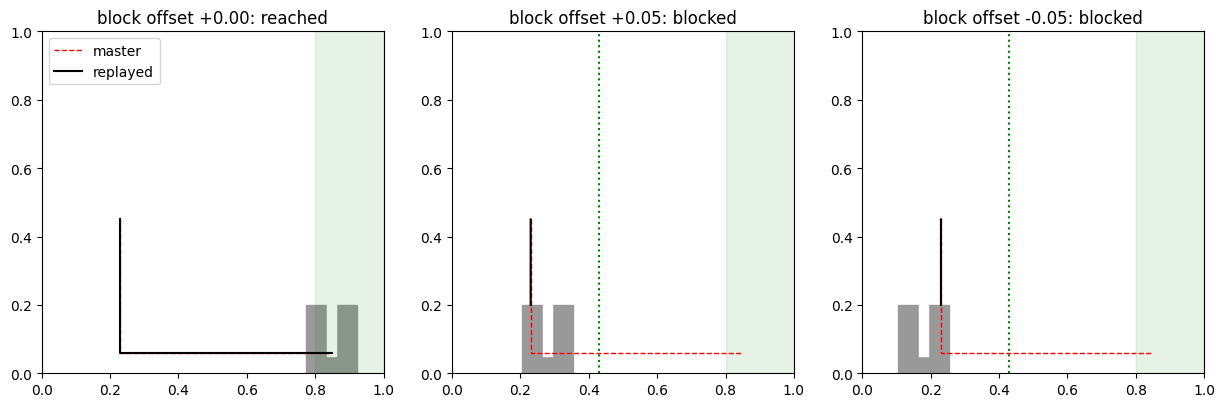

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, offset in zip(ax, (0.0, 0.05, -0.05), strict=True):
    world = Slide(offset)
    path = replay(world, MASTER, 3000)
    draw_world(a, world)  # as the replay left it
    a.plot(*MASTER[:, :2].T, "r--", lw=1, label="master")
    a.plot(*path[:, :2].T, "k", lw=1.5, label="replayed")
    a.set_title(
        f"block offset {offset:+.2f}: {'reached' if succeeded(world, path[-1]) else 'blocked'}"
    )
ax[0].legend()
plt.show()

### Demonstration
**Master.** The taught motion, resampled at $N_{\mathrm{m}} + 1$ points $\mathbf{m}_a$ equally spaced in arc length, with phase $\varphi_a = a / N_{\mathrm{m}}$ and length $S_{\mathrm{m}}$. It goes down into the slot and pushes right, never back over itself, so the phase rises continuously along it. It is taught upright, so its arc length is that of the tip.

**Datapoints.** $N_{\mathrm{d}}$ executions of the task in the taught world, each from its own start and at its own height in the slot, through the plant's actuator noise, aiming upright at every waypoint: the noise tilts the peg, and a demonstration that jams works the peg down as it tilts back. Every datapoint is a state one of them visited, so none lies inside the block or on the wrong side of the barrier. As in E2T2, where almost half the datapoints were taken inside the hole, importance is a count: $N_{\mathrm{p}}/2$ datapoints are drawn from all states and $N_{\mathrm{p}}/2$ from the insertion, the phases from the block's top to the slot's floor. Each datapoint is labelled with the phase of its nearest master sample in position, $\varphi_m = \varphi_{a^*}$, $a^* = \arg\min_a \|\mathbf{p}_m - \mathbf{p}(\mathbf{m}_a)\|$, $\mathbf{p}$ the tip's position: tilting does not move the task on.

In [6]:
N_M = 400  # master samples
N_DEMOS, N_P = 8, 200

seg = np.linalg.norm(np.diff(MASTER, axis=0), axis=1)
S_m = seg.sum()
s_grid = np.linspace(0, S_m, N_M + 1)
knots = np.concatenate([[0], np.cumsum(seg)])
master = np.column_stack([np.interp(s_grid, knots, MASTER[:, i]) for i in range(d)])
phi_master = s_grid / S_m


def phase_label(X):  # (n, d) -> (n,), the phase of the nearest master sample in position
    return phi_master[np.linalg.norm(X[:, None, :2] - master[None, :, :2], axis=2).argmin(axis=1)]


rng = np.random.default_rng(1)
demos = []
for _ in range(N_DEMOS):
    y_push = SLOT_FLOOR + rng.uniform(0.003, INSERTED - 0.003)
    start = MASTER[0] + np.append(rng.uniform(-0.05, 0.05, 2), 0.0)
    waypoints = np.array(
        [start, [C0 + rng.uniform(-CLEAR, CLEAR), y_push, 0.0], [MASTER[-1, 0], y_push, 0.0]]
    )
    world = Slide()
    demos.append(replay(world, waypoints, 3000, rng))
    assert succeeded(world, demos[-1][-1])

states = np.concatenate(demos)
phi_states = phase_label(states)
insertion = (phi_states >= (MASTER[0, 1] - BLOCK_TOP) / S_m) & (
    phi_states <= (MASTER[0, 1] - MASTER[1, 1]) / S_m
)
first = rng.choice(len(states), N_P // 2, replace=False)
rest = rng.choice(np.setdiff1d(np.flatnonzero(insertion), first), N_P // 2, replace=False)
pick = np.concatenate([first, rest])
X_p, phi_p = states[pick], phi_states[pick]
print(
    f"S_m = {S_m:.3f}; {len(states)} states from {N_DEMOS} demonstrations; {N_P} datapoints; "
    f"{sum(jammed(Slide(), s) for s in states)} jammed states"
)

S_m = 1.010; 2360 states from 8 demonstrations; 200 datapoints; 29 jammed states


### The cube
The tilt's wall is the widest tilt the demonstrations reached: the robot tilts no further than it was shown, and the datapoints are all inside the world. With it the world's box, and the cube around it, are fixed.


In [7]:
TILT_WALL = float(np.abs(states[:, 2]).max())
LO = np.array([0.0, 0.0, -TILT_WALL])
SIDE = np.array([WORLD, WORLD, 2 * TILT_WALL])
MARGIN = SIDE / (2 * (K - 1))
CUBE_LO, L = LO - MARGIN, SIDE + 2 * MARGIN  # the law's cube, [CUBE_LO, CUBE_LO + L] per axis
print(f"tilt wall {TILT_WALL / DEPTH:.3f} rad; cube sides {L.round(3)}")

tilt wall 0.335 rad; cube sides [1.111 1.111 0.112]


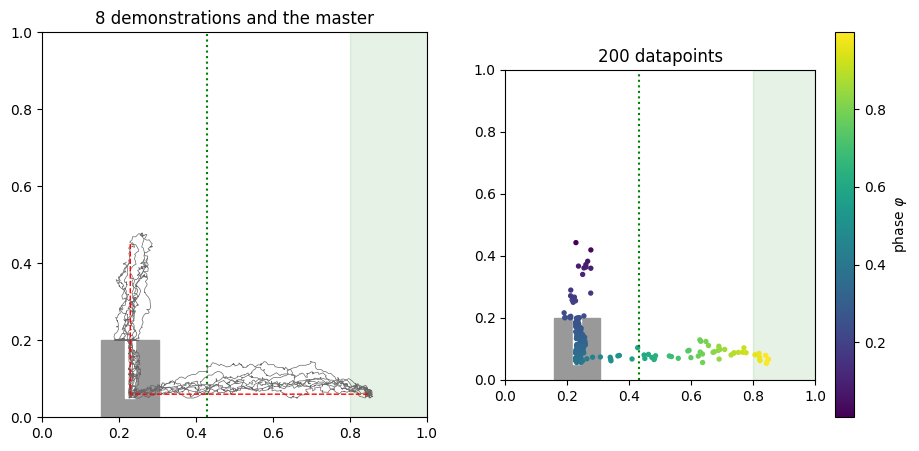

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a in ax:
    draw_world(a, Slide())
for path_ in demos:
    ax[0].plot(*path_[:, :2].T, "-", color="0.4", lw=0.5)
ax[0].plot(*master[:, :2].T, "r--", lw=1)
ax[0].set_title(f"{N_DEMOS} demonstrations and the master")
sc = ax[1].scatter(*X_p[:, :2].T, c=phi_p, s=8, cmap="viridis")
fig.colorbar(sc, ax=ax[1], label=r"phase $\varphi$")
ax[1].set_title(f"{N_P} datapoints")
plt.show()

### The sliding target
**Kernels.** Each datapoint $\mathbf{x}_m$ is an isotropic Gaussian of width $h$, **reflected at the cube's faces** (method of images), so it has mass exactly 1 inside $\Omega$:
$$g_i(y; \mu) = \sum_{n \in \mathbb{Z}} \big[\mathcal{N}(y;\, \mu + 2nL_i,\, h^2) + \mathcal{N}(y;\, 2a_i - \mu + 2nL_i,\, h^2)\big].$$
Unfolding the images onto the real line, $\int_{a_i}^{a_i+L_i} g_i(y;\mu)\,\phi^{(i)}_k(y)\,dy = \int_{\mathbb{R}} \mathcal{N}(y; \mu, h^2) \cos(\pi k (y - a_i) / L_i)\, dy$, so its coefficients are exact and separable,
$$\hat{\mathcal{W}}^{(m)}_{\mathbf{k}} = \prod_{i=1}^d c^{(i)}_{k_i}(x_{m,i}), \qquad c^{(i)}_k(\mu) = e^{-(\pi k h / L_i)^2 / 2} \cos(\pi k (\mu - a_i) / L_i),$$
a rank-1 TT per datapoint, with no TT-cross and no renormalisation.

**Width.** $h$ maximises the leave-one-out likelihood of the datapoints under their own kernel density, $\sum_m \log \frac{1}{N_{\mathrm{p}} - 1} \sum_{n \ne m} \prod_i g_i(x_{m,i}; x_{n,i})$.

**Sliding.** The target holds the datapoints from the phase $\varphi$ up to two resolvable widths ahead of it:
$$\hat{\mathcal{W}}(\varphi) = \sum_m w_m(\varphi)\, \hat{\mathcal{W}}^{(m)}, \qquad w_m(\varphi) \propto \sigma\Big(\frac{\varphi + 2\delta - \varphi_m}{\varepsilon}\Big)\, \sigma\Big(\frac{\varphi_m - \varphi}{\varepsilon}\Big), \qquad \sum_m w_m = 1,$$
with $\sigma$ the logistic function and $\delta = \varepsilon = \sigma_{\mathrm{f}} = \max(h,\ L_1 / (K - 1)) / S_{\mathrm{m}}$. The law sees nothing narrower in position than $L_1 / (K - 1)$, the half-period of its finest mode, so an edge closer than that would add nothing it can see. The back edge sits at the phase itself, not behind it: a window reaching behind the phase holds half its weight in stages already done, which the forgetting statistic lets decay and the law then turns back to, so it lingers instead of progressing. The back edge is also what makes forgetting safe: a stage the statistic has forgotten but the target still held would count as uncovered again and draw the law back to it, away from the push.

**Retry.** The phase is estimated from the pose alone, so in a deviating world it can read a later stage although an earlier one never succeeded, and the stage to redo then lies behind the window. An **advance** is the phase rising $\delta$ above the lowest phase since the last advance, $\delta$ being the smallest change the law can see, so noise is no advance and a retry that falls back and succeeds again is one. During a **stall**, the time $\tau$ since the last advance, the back edge retreats,
$$w_m(\varphi) \propto \sigma\Big(\frac{\varphi + 2\delta - \varphi_m}{\varepsilon}\Big)\, \sigma\Big(\frac{\varphi_m - \varphi + \rho}{\varepsilon}\Big), \qquad \rho = \delta\, \frac{\tau}{T_{\mathrm{f}}},$$
one stage behind per forgetting horizon: by the time the statistic has forgotten half of a stage, the stage before it is back in the target. Retreating at the master's own speed instead would open the whole past within a jam of a few seconds, which looks the same as a stall. An advance resets $\rho$ to $0$, and each trial restarts the clock. E2T2's static target is $w_m = 1 / N_{\mathrm{p}}$. The sum is built as one TT with diagonal cores and rounded; no rank of a TT with $K$ entries on an end axis can exceed $K$ at $d = 3$, so the rounding loses nothing.

In [9]:
def g(y, mu, h, i):  # Gaussian reflected at the cube's faces on axis i, broadcast over y and mu
    n = 2 * L[i] * np.arange(-2, 3)  # images beyond |n| = 2 lie more than 3L away
    images = np.concatenate([mu[..., None] + n, 2 * CUBE_LO[i] - mu[..., None] + n], axis=-1)
    return np.exp(-((y[..., None] - images) ** 2) / (2 * h**2)).sum(-1) / (np.sqrt(2 * np.pi) * h)


def loo_log_likelihood(h):
    G = np.prod([g(X_p[:, None, i], X_p[None, :, i], h, i) for i in range(d)], axis=0)
    np.fill_diagonal(G, 0.0)
    return np.log(G.sum(axis=1) / (N_P - 1)).sum()


h = float(
    np.exp(
        minimize_scalar(
            lambda lh: -loo_log_likelihood(np.exp(lh)), bounds=np.log([1e-3, 0.3]), method="bounded"
        ).x
    )
)
sigma_f = max(h, L[0] / (K - 1)) / S_m
delta = eps_f = sigma_f
C = [
    np.exp(-((np.pi * np.arange(K) * h / L[i]) ** 2) / 2)
    * np.cos(np.pi * np.arange(K) * (X_p[:, [i]] - CUBE_LO[i]) / L[i])
    for i in range(d)
]  # (N_P, K) per axis


def weights(phi, rho=0.0):  # (N_P,), of sum 1; rho: the back edge's retreat
    w = 1.0 / (1.0 + np.exp(-(phi + 2 * delta - phi_p) / eps_f))
    w = w / (1.0 + np.exp(-(phi_p - phi + rho) / eps_f))  # the back edge
    return w / w.sum()


def tt_weighted_sum(
    rows, w
):  # rows: (M, K) per axis -> the TT of sum_m w_m rows_1[m] o ... o rows_d[m]
    cores = [(w[:, None] * rows[0]).T[None]]
    cores += [np.einsum("mk,mn->mkn", rows[i], np.eye(len(w))) for i in range(1, d - 1)]
    cores += [rows[-1][:, :, None]]
    return tt.vector.from_list(cores).round(1e-10)


def target(w):  # the TT of sum_m w_m W^(m)
    return tt_weighted_sum(C, w)


print(f"h = {h:.4f}, sigma_f = delta = eps = {sigma_f:.4f}")

h = 0.0096, sigma_f = delta = eps = 0.1222


phi = 0.15: weight within delta of it 0.33
phi = 0.35: weight within delta of it 0.87
phi = 1.0: weight within delta of it 0.47


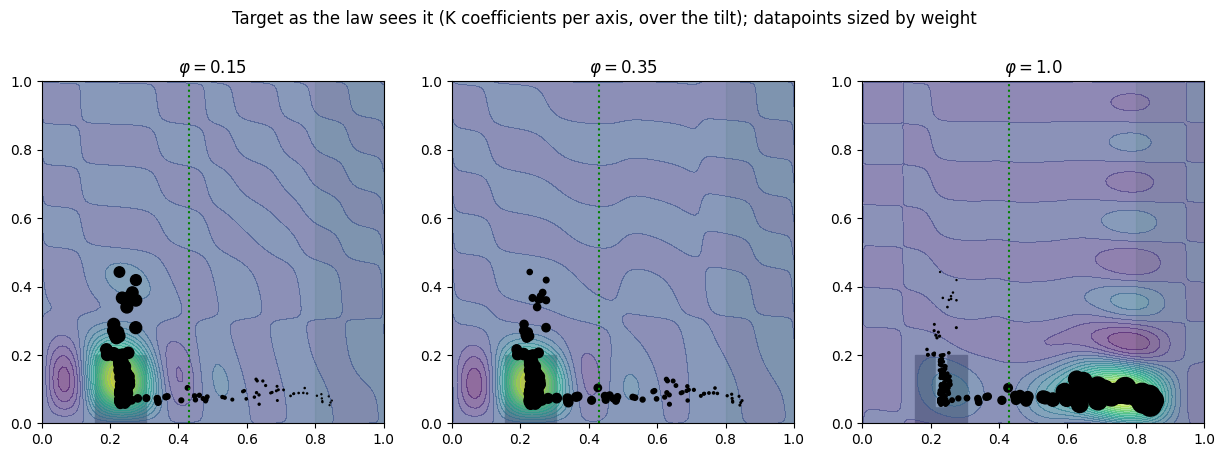

In [10]:
xa = np.linspace(0, WORLD, 101)


# The density the K^d coefficients describe, marginalised over the tilt, on the grid xa x xa,
# indexed [y, x]: the tilt's k = 0 integrates to 1 over its axis, every other k to 0.
def density(ttW):
    B = [
        np.array([Phi(u, i) for u in xa]) / np.where(np.arange(K) == 0, L[i], L[i] / 2)
        for i in range(2)
    ]
    return (B[0] @ ttW.full().reshape(K, K, K)[:, :, 0] @ B[1].T).T


fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, phi in zip(ax, (0.15, 0.35, 1.0), strict=True):
    draw_world(a, Slide())
    a.contourf(xa, xa, density(target(weights(phi))), levels=20, alpha=0.6)
    a.scatter(*X_p[:, :2].T, s=40 * N_P * weights(phi), c="k")
    a.set_title(rf"$\varphi = {phi}$")
    print(
        f"phi = {phi}: weight within delta of it {weights(phi)[abs(phi_p - phi) <= delta].sum():.2f}"
    )
fig.suptitle(
    "Target as the law sees it (K coefficients per axis, over the tilt); datapoints sized by weight"
)
plt.show()

### Weights of the ergodic metric
$$\mathbf{\Lambda}_{\mathbf{k}} = (1 + \|\mathbf{k}\|^2)^{-\frac{d+1}{2}}, \qquad \xi = \sum_{\mathbf{k}} \mathbf{\Lambda}_{\mathbf{k}} \big(\mathcal{W}_{\mathbf{k}} - \hat{\mathcal{W}}_{\mathbf{k}}\big)^2.$$
Built by TT-cross and TT-rounded, as in E2T2.

In [11]:
def Lambda_func(idx):  # multi-indices k (M, d) -> (M,)
    return (1.0 + np.linalg.norm(idx.reshape(-1, d), axis=1) ** 2) ** (-(d + 1) / 2)


ttLambda = rect_cross(Lambda_func, x0=tt.rand(K, d, r=1), nswp=15, kickrank=1, eps=1e-4)
ttLambda = ttLambda.round(1e-2)
print("Rank of ttLambda:", ttLambda.r)

Rank of ttLambda: [1 3 3 1]


### Spatial statistic with forgetting
E2T2's time average $\mathcal{W}(t) = \frac{1}{t}\int_0^t \mathbf{\Phi}(\mathbf{x}(\tau))\,d\tau$ weighs the first second of a run as much as the last, so coverage once gained is never lost. With forgetting it becomes a normalised, exponentially weighted average:
$$\mathbf{A}(\ell) = \lambda\, \mathbf{A}(\ell - 1) + \Delta t\, \mathbf{\Phi}(\mathbf{x}_\ell), \qquad Z(\ell) = \lambda\, Z(\ell - 1) + \Delta t, \qquad \mathcal{W}(\ell) = \frac{\mathbf{A}(\ell)}{Z(\ell)}, \qquad \lambda = e^{-\Delta t / T_{\mathrm{f}}}.$$
$\lambda = 1$ is E2T2's average exactly. The horizon's half-life is the master's duration, the time one pass along it takes at full speed: when such a pass ends, its start still holds half its weight,
$$T_{\mathrm{f}} = \frac{S_{\mathrm{m}} / u_{\max}}{\ln 2}.$$ Scaling a TT by $\lambda$ is exact and keeps its rank; only the added rank-1 $\mathbf{\Phi}$ raises it, so $\mathbf{A}$ is TT-rounded every `FLUSH` steps, as in E2T2.

In [12]:
T_F = (S_m / (V_MAX / DT)) / np.log(2)  # s
FLUSH = 5
RMAX = K ** (d // 2)  # the highest rank a TT of K^d entries can have: rounding loses only eps


@dataclass
class Statistic:
    lam: float  # forgetting factor per step; 1 is E2T2's time average
    ttA: tt.vector = None
    Z: float = 0.0
    n: int = 0

    def add(self, tt_phi):
        self.ttA = tt_phi * DT if self.ttA is None else self.ttA * self.lam + tt_phi * DT
        self.Z, self.n = self.lam * self.Z + DT, self.n + 1
        if self.n % FLUSH == 0:
            self.ttA = self.ttA.round(1e-6, RMAX)

    def W(self):
        return self.ttA * (1 / self.Z)


lam_f = np.exp(-DT / T_F)
print(f"T_f = {T_F:.2f} s, lambda = {lam_f:.5f}")

T_f = 3.64 s, lambda = 0.99726


### Phase
The target needs to know how far the task has come. The phase $\tilde{\varphi}$ is the posterior mean of a Bayesian filter over the master's samples, with belief $\beta_\ell(a)$:
$$\beta_\ell(a) \propto \mathcal{N}(\mathbf{p}_\ell;\, \mathbf{p}(\mathbf{m}_a),\, h^2 \mathbf{I}) \sum_{a'} \mathcal{N}(s_a - s_{a'};\, 0,\, \sigma_\ell^2)\, \beta_{\ell-1}(a'), \qquad \sigma_\ell = \max\big(\|\mathbf{p}_\ell - \mathbf{p}_{\ell-1}\|,\ S_{\mathrm{m}} / N_{\mathrm{m}}\big), \qquad \tilde{\varphi}_\ell = \sum_a \beta_\ell(a)\, \varphi_a,$$
where $s_a$ is the arc length of sample $a$ and $\mathbf{p}$ the tip's position: tilting does not move the task on, so the phase ignores it. The transition is a random walk in arc length as wide as the tip actually moved, since the position along the master cannot change by more than that; it is symmetric, so it assumes no direction of progress and the phase may fall. The likelihood uses the target's own kernel width $h$. The first belief is the likelihood alone. The update runs in log space over every pair of samples, so a tip far from where the belief sits cannot underflow it to zero.

In [13]:
ARC2 = (s_grid[:, None] - s_grid[None]) ** 2  # squared arc-length distances between samples


@dataclass
class PhaseFilter:
    log_belief: np.ndarray = None
    x_prev: np.ndarray = None

    def update(self, x):  # -> the posterior mean phase
        log_lik = -((master[:, :2] - x[:2]) ** 2).sum(axis=1) / (2 * h**2)
        if self.log_belief is None:
            log_belief = log_lik
        else:
            sigma = max(np.linalg.norm(x[:2] - self.x_prev[:2]), S_m / N_M)
            log_belief = logsumexp(self.log_belief[None] - ARC2 / (2 * sigma**2), axis=1) + log_lik
        self.log_belief = log_belief - logsumexp(log_belief)
        self.x_prev = x
        return float(np.exp(self.log_belief) @ phi_master)

### One trial
Each step, at the measured state $\mathbf{x}_\ell$: the phase $\tilde{\varphi}_\ell$, the target $\hat{\mathcal{W}}(\tilde{\varphi}_\ell)$, the statistic with $\mathbf{\Phi}(\mathbf{x}_\ell)$ added, and the direction (E2T2, Eq. (4))
$$b_i = \sum_{\mathbf{k}} \mathbf{\Lambda}_{\mathbf{k}} \big(\mathcal{W}_{\mathbf{k}} - \hat{\mathcal{W}}_{\mathbf{k}}(\tilde{\varphi})\big) \nabla_i \mathbf{\Phi}_{\mathbf{k}}(\mathbf{x}_\ell), \qquad \mathbf{x}_{\ell+1} = \mathrm{step}\Big(\mathbf{x}_\ell,\ \mathbf{x}_\ell - u_{\max} \Delta t\, \frac{\mathbf{b}}{\|\mathbf{b}\|} + \boldsymbol{\nu}_\ell\Big),$$
with $\boldsymbol{\nu}_\ell$ the actuator noise and `step` the world. The minus sign is missing in the paper's Eq. (4) but needed, as the E2T2 code has it. E2T2 itself is the static target with $\lambda = 1$. A trial starts at the master's start and ends at the goal, or after `MAX_STEPS`; the statistic is passed in, so a sequence of trials can hand it on. Beside the dead-end share a trial reports the share of its steps spent jammed.

In [14]:
MAX_STEPS = 5000
STATIC = target(np.full(N_P, 1 / N_P))


def run_trial(world, stat, sliding, rng, retry=False):
    x, filt = MASTER[0].copy(), PhaseFilter()
    path, phis, dead, jam = [x], [], [in_dead_end(world, x)], [jammed(world, x)]
    lowest, stall, retried, rhos = (
        np.inf,
        0,
        [],
        [],
    )  # lowest: the lowest phase since the last advance
    cs, bars = [world.c], [world.barrier]
    for _ in range(MAX_STEPS):
        phi = filt.update(x)
        lowest = min(lowest, phi)
        lowest, stall = (phi, 0) if phi >= lowest + delta else (lowest, stall + 1)
        rho = delta * stall * DT / T_F if retry else 0.0
        retried.append(rho >= delta)
        rhos.append(rho)
        tt_phi, tt_dphi = tt_phi_dphi(x)
        stat.add(tt_phi)
        ttW_hat = target(weights(phi, rho)) if sliding else STATIC
        ttVdW = ttLambda * (stat.W() - ttW_hat)
        b = np.array([tt.dot(ttVdW, tt_dphi[i]) for i in range(d)])
        x = step(world, x, x - V_MAX * b / np.linalg.norm(b) + rng.uniform(-NOISE, NOISE, d))
        path.append(x)
        phis.append(phi)
        dead.append(in_dead_end(world, x))
        cs.append(world.c)
        bars.append(world.barrier)
        jam.append(jammed(world, x))
        if succeeded(world, x):
            break
    dead = np.array(dead)
    return {
        "path": np.array(path),
        "phi": np.array(phis),
        "rho": np.array(rhos),
        "c": np.array(cs),  # the block's centre, per state of path
        "barrier": np.array(bars),
        "steps": len(phis),
        "success": succeeded(world, x),
        "dead_ends": int((dead[1:] & ~dead[:-1]).sum()),
        "inserted": not world.barrier,  # a failure that inserted is a slip-out, one that did not never inserted
        "dead_share": float(dead.mean()),
        "jam_share": float(np.mean(jam)),
        "retry_share": float(np.mean(retried)),  # a stage or more behind back in the target
    }

### One trial in the taught world
The sliding law with forgetting, and E2T2 for comparison: the path coloured by phase, and the phase over the trial.

A trial that inserts but leaves the slot mid-push does not recover: the target is fixed in the world, so it sends the tip back to where the slot was taught. That is the week-6 limit of a world-frame target, out of scope here, and counted as its own failure.

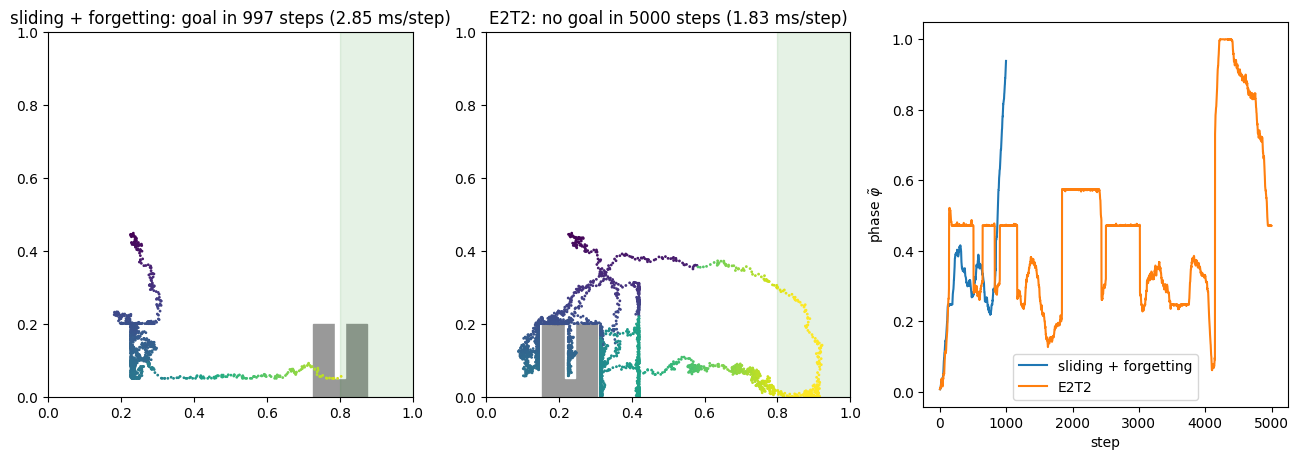

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, (name, sliding, lam) in zip(
    ax[:2], (("sliding + forgetting", True, lam_f), ("E2T2", False, 1.0)), strict=True
):
    world = Slide()
    t0 = time.time()
    r = run_trial(world, Statistic(lam), sliding, np.random.default_rng(0))
    draw_world(a, world)
    a.scatter(*r["path"][1:, :2].T, c=r["phi"], s=1, vmin=0, vmax=1)
    a.set_title(
        f"{name}: {'goal' if r['success'] else 'no goal'} in {r['steps']} steps ({1e3 * (time.time() - t0) / r['steps']:.2f} ms/step)"
    )
    ax[2].plot(r["phi"], label=name)
ax[2].set(xlabel="step", ylabel=r"phase $\tilde\varphi$")
ax[2].legend()
plt.show()

### One trial with the block displaced
The block $0.09$ to either side of where it was taught, so the taught descent lands beside it. The sliding law with forgetting, and E2T2, on the same noise.

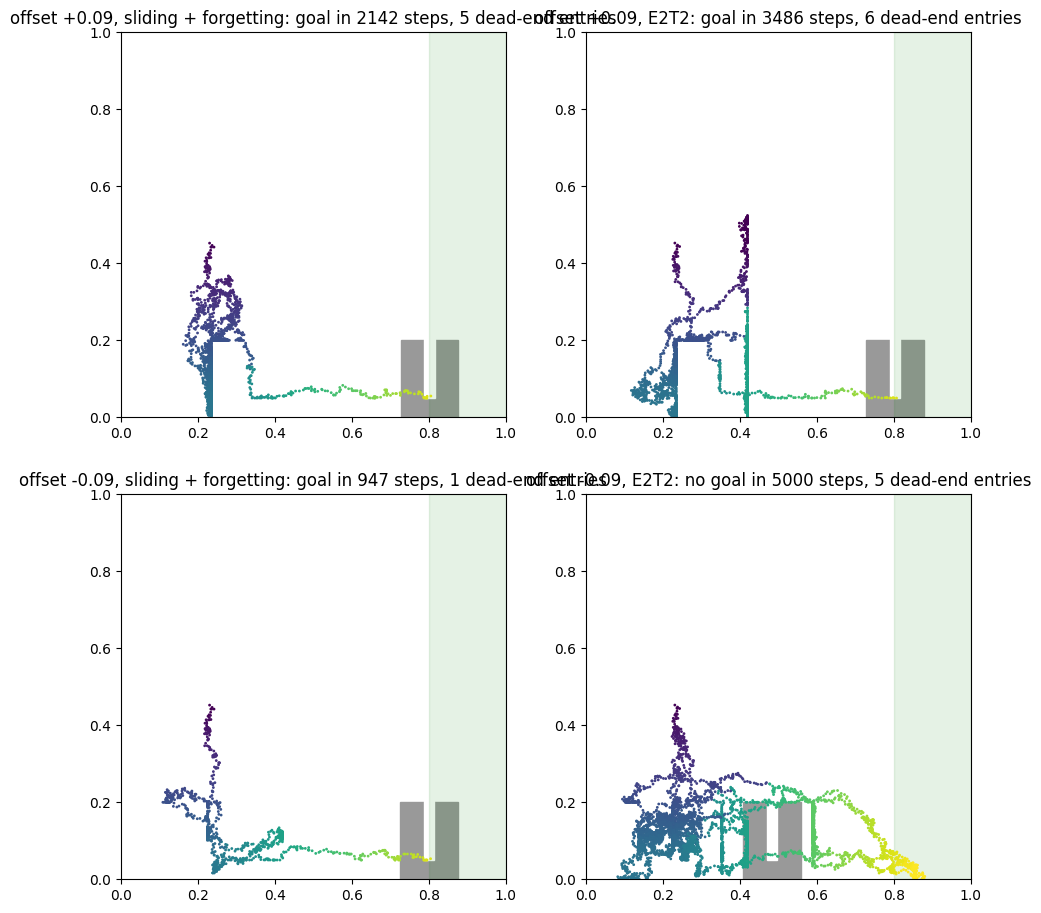

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(11, 11))
for row, offset in zip(ax, (0.09, -0.09), strict=True):
    for a, (name, sliding, lam) in zip(
        row, (("sliding + forgetting", True, lam_f), ("E2T2", False, 1.0)), strict=True
    ):
        world = Slide(offset)
        r = run_trial(world, Statistic(lam), sliding, np.random.default_rng(1))
        draw_world(a, world)
        a.scatter(*r["path"][1:, :2].T, c=r["phi"], s=1, vmin=0, vmax=1)
        a.set_title(
            f"offset {offset:+.2f}, {name}: {'goal' if r['success'] else 'no goal'} in {r['steps']} steps, {r['dead_ends']} dead-end entries"
        )
plt.show()

### A sequence of trials
As in E2T2, a trial ends at the goal or after `MAX_STEPS`, and the next one starts at the master's start with the block back where the sequence put it. Only the state and the world are reset: the statistic is handed on, since the paper's re-initialisation is instantaneous. The noise of trial $c$ in sequence $s$ is seeded by $(s, c)$, so every setting sees the same noise. The experiments are in `Sequential_E2T2_peg_slide_2D_experiments.ipynb`.

In [17]:
METHODS = {  # name -> (sliding, lambda, retry)
    "E2T2": (False, 1.0, False),
    "sliding + forgetting": (True, lam_f, False),
    "sliding + forgetting + retry": (True, lam_f, True),
}


def run_sequence(sliding, lam, retry, offset, seq, n_trials=10):
    stat = Statistic(lam)
    return [
        run_trial(Slide(offset), stat, sliding, np.random.default_rng([seq, c]), retry)
        for c in range(n_trials)
    ]

### One sequence
The block $0.09$ to the left, each method: the paths of the sliding law by trial, and the steps per trial (a trial that fails counts `MAX_STEPS`).

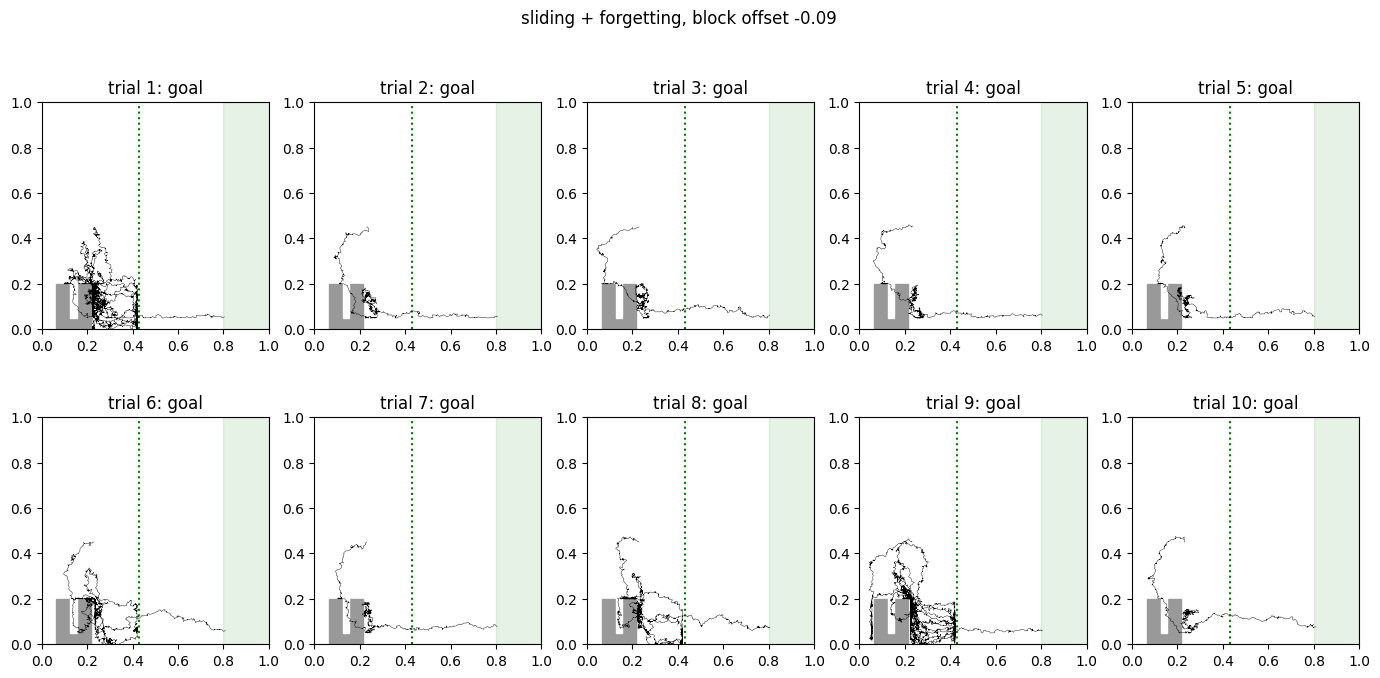

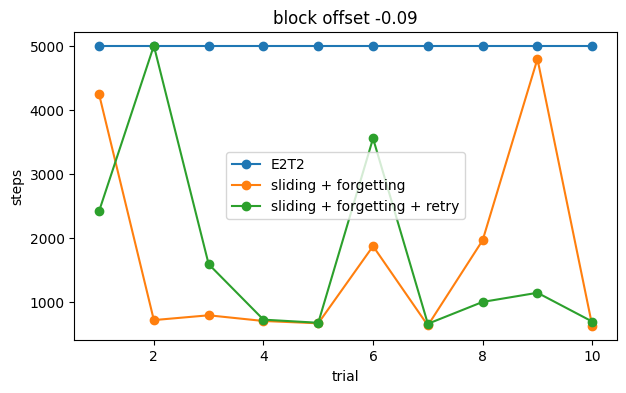

In [18]:
OFFSET = -0.09
with Pool(len(METHODS)) as pool:
    seq0 = dict(
        zip(
            METHODS,
            pool.starmap(run_sequence, [(*s, OFFSET, 0) for s in METHODS.values()]),
            strict=True,
        )
    )

fig, ax = plt.subplots(2, 5, figsize=(17, 7.5))
for c, a in enumerate(ax.flat):
    r = seq0["sliding + forgetting"][c]
    draw_world(a, Slide(OFFSET))
    a.plot(*r["path"][:, :2].T, "k", lw=0.3)
    outcome = "goal" if r["success"] else "slip-out" if r["inserted"] else "never inserted"
    a.set_title(f"trial {c + 1}: {outcome}")
fig.suptitle(f"sliding + forgetting, block offset {OFFSET:+.2f}")
plt.show()

fig, a = plt.subplots(figsize=(7, 4))
for m, trials in seq0.items():
    a.plot(range(1, len(trials) + 1), [r["steps"] for r in trials], "o-", label=m)
a.set(xlabel="trial", ylabel="steps", title=f"block offset {OFFSET:+.2f}")
a.legend()
plt.show()

## Checks
Each compares against an independent computation, not against a printed value.

**Basis gradient**: $\nabla_i \mathbf{\Phi}$ from `tt_phi_dphi` against a central difference of $\mathbf{\Phi}$.

In [19]:
x_c, eps = np.array([0.37, 0.81, 0.3 * TILT_WALL]), 1e-6
for i in range(d):
    e = eps * np.eye(d)[i]
    fd = (tt_phi_dphi(x_c + e)[0].full() - tt_phi_dphi(x_c - e)[0].full()) / (2 * eps)
    print(f"axis {i}: max |grad - fd| =", np.abs(tt_phi_dphi(x_c)[1][i].full() - fd).max())

axis 0: max |grad - fd| = 3.3292657519723434e-09
axis 1: max |grad - fd| = 1.456104570252137e-09
axis 2: max |grad - fd| = 2.104554710058437e-06


**Environment**: rigid replays of the master, upright. In the taught world it reaches the goal; with the block $0.05$ to either side it lands on the block's top and stays there; pushing the block before the insertion, from inside the slot or from beside the block, ends at the barrier or at the block.

In [20]:
for offset in (0.0, 0.05, -0.05):
    world = Slide(offset)
    s = replay(world, MASTER, 3000)[-1]
    print(f"offset {offset:+.2f}: succeeded {succeeded(world, s)}, tip {s.round(3)}")
    assert succeeded(world, s) == (offset == 0.0)
    assert offset == 0.0 or abs(s[1] - BLOCK_TOP) < 1e-9

world = Slide()
shallow = np.array(
    [[C0, 0.45, 0.0], [C0, 0.10, 0.0], [0.85, 0.10, 0.0]]
)  # into the slot, not to its floor
s = replay(world, shallow, 3000)[-1]
print(f"push without full insertion: block at {world.c:.3f}, barrier {world.barrier}")
assert world.barrier and world.c == BARRIER_X - PEG - BLOCK_HALF

world = Slide()
s = replay(world, np.array([[0.05, 0.05, 0.0], [0.85, 0.05, 0.0]]), 3000)[-1]
print(
    f"push from beside the block: tip x {s[0]:.3f}, block at {world.c:.3f}, dead end {in_dead_end(world, s)}"
)
assert world.c == C0 and in_dead_end(world, s)

offset +0.00: succeeded True, tip [0.85 0.06 0.  ]


offset +0.05: succeeded False, tip [0.23 0.2  0.  ]


offset -0.05: succeeded False, tip [0.23 0.2  0.  ]
push without full insertion: block at 0.345, barrier True


push from beside the block: tip x 0.145, block at 0.230, dead end True


**Kernel target**: the closed form against E2T2's route, in two parts. On each axis, the coefficients $c^{(i)}_k(\mu)$ against Gauss-Legendre quadrature of the reflected kernel $g_i$ against $\phi^{(i)}_k$, with a few nodes per kernel width, at every datapoint; and $g_i$ must have mass 1 inside the cube. Then the TT of the weighted sum at $\varphi = 0.35$ against the dense sum $\sum_m w_m\, \mathbf{c}^{(1)}_m \circ \mathbf{c}^{(2)}_m \circ \mathbf{c}^{(3)}_m$. E2T2's TT-cross of the whole density is out of reach at $d = 3$: a few nodes per kernel width make a grid of $10^7$ points.


In [21]:
for i in range(d):
    n = int(np.ceil(4 * L[i] / h))  # quadrature nodes, a few per kernel width
    u, wq = np.polynomial.legendre.leggauss(n)
    yq, wq = CUBE_LO[i] + 0.5 * L[i] * (u + 1.0), 0.5 * L[i] * wq
    G = g(yq[None, :], X_p[:, [i]], h, i)  # (N_P, n)
    quad = (G * wq) @ np.cos(np.pi * (yq[:, None] - CUBE_LO[i]) * np.arange(K) / L[i])
    mass = (G @ wq).min(), (G @ wq).max()
    print(
        f"axis {i}: n = {n}, mass in [{mass[0]:.12f}, {mass[1]:.12f}], max |c - quadrature| = {np.abs(quad - C[i]).max():.2e}"
    )

w_chk = weights(0.35)
dense = np.einsum("m,mi,mj,mk->ijk", w_chk, *C)
print(f"max |W_tt - W_dense| = {np.abs(target(w_chk).full() - dense).max():.2e}")

axis 0: n = 462, mass in [1.000000000000, 1.000000000000], max |c - quadrature| = 1.78e-14
axis 1: n = 462, mass in [1.000000000000, 1.000000000000], max |c - quadrature| = 1.82e-14
axis 2: n = 47, mass in [1.000000000000, 1.000000000000], max |c - quadrature| = 3.77e-15
max |W_tt - W_dense| = 2.89e-15


**Forgetting statistic**: the TT accumulator against the dense recursion $\mathbf{A} \leftarrow \lambda \mathbf{A} + \Delta t\, \mathbf{\Phi}(\mathbf{x})$ on a random walk of 2000 steps through the world's box, on every one of the $K^d$ coefficients, with forgetting and without.

In [22]:
walk = np.clip(
    LO + SIDE / 2 + np.cumsum(np.random.default_rng(2).uniform(-V_MAX, V_MAX, (2000, d)), axis=0),
    LO,
    LO + SIDE,
)
for lam in (lam_f, 1.0):
    stat, A, Z = Statistic(lam), np.zeros((K,) * d), 0.0
    for x_ in walk:
        stat.add(tt_phi_dphi(x_)[0])
        A = lam * A + DT * np.einsum("i,j,k->ijk", *(Phi(x_[i], i) for i in range(d)))
        Z = lam * Z + DT
    err = np.abs(stat.W().full() - A / Z).max() / np.abs(A / Z).max()
    print(
        f"lambda = {lam:.5f}: Z = {stat.Z:.4f} (dense {Z:.4f}), max relative |W_tt - W_dense| = {err:.1e}"
    )

lambda = 0.99726: Z = 3.6328 (dense 3.6328), max relative |W_tt - W_dense| = 1.6e-06


lambda = 1.00000: Z = 20.0000 (dense 20.0000), max relative |W_tt - W_dense| = 4.6e-07


**Phase filter**: on the master replayed without noise its phase rises with the arc length and never falls by more than one sample; on a replay that goes down into the slot and back up to the start it falls back.

In [23]:
world = Slide()
path_ = replay(world, MASTER, 3000)
filt = PhaseFilter()
phi_ = np.array([filt.update(x_) for x_ in path_])
true_ = phase_label(path_)
print(
    f"along the master: largest fall {max(0.0, -np.diff(phi_).min()):.1e}, max |phase - arc length| {np.abs(phi_ - true_).max():.4f}"
)
assert -np.diff(phi_).min() < 1 / N_M

filt = PhaseFilter()
back = replay(Slide(), np.array([MASTER[0], MASTER[1], MASTER[0]]), 3000)
phi_ = np.array([filt.update(x_) for x_ in back])
print(f"down and back up: peak {phi_.max():.3f}, end {phi_[-1]:.3f}")
assert phi_.max() > 0.35 and phi_[-1] < 0.02

along the master: largest fall 4.6e-04, max |phase - arc length| 0.0108


down and back up: peak 0.380, end 0.008


**Jam**: `width` against the peg's outline, sampled finely along its two sides and its end face and cut at the block's top, over depths and tilts of either sign. Then the claim the clearance is set for: noisy replays of the master in the taught world, aiming upright, jam on the way down more often than not.


In [24]:
def width_sampled(depth, theta, n=400001):
    # The tip at the origin, the peg's axis tilted by theta from vertical, cut at y = depth.
    axis, normal = (
        np.array([np.sin(theta), np.cos(theta)]),
        np.array([np.cos(theta), -np.sin(theta)]),
    )
    t = np.linspace(0.0, 1.0, n)[:, None]
    long = 2 * (depth + PEG) / np.cos(theta)  # longer than any side below the top
    outline = np.concatenate(
        [sgn * PEG * normal + t * long * axis for sgn in (-1, 1)] + [(2 * t - 1) * PEG * normal]
    )
    below = outline[outline[:, 1] <= depth]
    return below[:, 0].max() - below[:, 0].min()


err = max(
    abs(width(dep, th) - width_sampled(dep, th))
    for dep in (0.01, 0.08, DEPTH)
    for th in (-0.5, -0.05, 0.0, NOISE / DEPTH, 0.2, 0.8)
)
print(f"max |width - sampled outline| = {err:.1e}")
assert err < 1e-5

starts, n_jam, n_in = 40, 0, 0
for k in range(starts):
    path_ = replay(Slide(), MASTER, 3000, np.random.default_rng([7, k]))
    k_in = np.flatnonzero(path_[:, 1] <= SLOT_FLOOR + INSERTED)
    down = path_[: k_in[0] + 1] if len(k_in) else path_  # the block stays home on the way down
    n_jam += any(jammed(Slide(), s) for s in down)
    n_in += len(k_in) > 0
print(f"noisy replays: {n_jam} of {starts} jam on the way down, {n_in} reach the slot's floor")
assert n_jam > starts / 2

max |width - sampled outline| = 7.8e-07


noisy replays: 28 of 40 jam on the way down, 40 reach the slot's floor
